In [54]:
import pandas as pd
import numpy as np
import h5py
from pathlib import Path
import matplotlib.pyplot as plt


In [26]:
def ad_to_ph(ad, dp=[], miss_val=-1, rng=None, seed=None, verbose=False):
    """Transform allele depths to pseudo-haploid genotypes
    
    For each SNP/individual, p is the fraction of reads supporting the
    altnerate allele. To simulate randomly sampling a single read
    (weighted by how many ref vs. alt reads were observed), draw a
    uniform random number between 0, 1 and compare it to p. since a uniform
    draw falls below p with probability p, this comparison
    (i.e., a weighted coin flip) reproduces the observed allele proportions.
    True/False (i.e., the random draw is greater or less than p) is then transformed to 1/0 to get the final pseudohap call.

    ad: Allele Counts in format [n_snps, n_iids, 2]
    dp: Depths [n_snps, n_iids], if not given, calculate from ad
    rng: np.random.Generator to use for the random draw, e.g.
        rng_set = np.random.default_rng(42); if None, an unseeded
        default_rng() is created (results won't be reproducible)
    seed: (optional) the seed value used to create rng, purely for
        logging/display; !! has no effect on the actual random draw !!
    verbose: if True, print which seed/rng was used
    Return ph: [n_snps, n_iids], pseudo-haploid genotypes 0,1"""
    if rng is None:
        print("Warning: no rng passed to ad_to_ph — using an unseeded "
              "generator, results will NOT be reproducible.")
        rng = np.random.default_rng()
    elif verbose:
        if seed is not None:
            print(f"ad_to_ph: using rng seeded with {seed}, outside of this function")
        else:
            print("ad_to_ph: using provided rng (seed not tracked)")
    if len(dp)==0:
        dp = np.sum(ad, axis=2)
    idx_miss = (dp == 0)
    dp[idx_miss] = 1
    p = ad[:,:,1] / dp
    
    ph = (rng.random(size=np.shape(p)) < p).astype(np.int8)
    ph[idx_miss] = miss_val
    return ph

In [27]:
# set paths
path_vcf = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/high_cov/bricei_only_variants_chr.maf05.vcf.gz"
path_h5 = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/high_cov/bricei_only_variants_chr.maf05.h5"
out_prefix = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov"
pop_label = "HighCov"

snp_path = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov.snp"
# note that the chr ids had to be swapped to match. 
lowcov_path = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/low_cov_pseudohap.renamed.haplo"
output_dir = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps"

# read in high-cov
h5 = h5py.File(path_h5, mode="r")
samples = h5["samples"][:].astype(str)
ad = h5["calldata/AD"][:, :, :2]

rng_set = np.random.default_rng(16)
ph = ad_to_ph(ad, rng=rng_set)  # 0 = ref allele called, 1 = alt allele called, -1 = missing

snps = pd.read_csv(
    snp_path, sep=r"\s+", header=None,
    names=["snp_id", "chr", "gen_pos", "pos", "ref", "alt"]
)

# ---- Load low-coverage data ----
lowcov = pd.read_csv(lowcov_path, sep="\t")
ind_cols = [c for c in lowcov.columns if c.startswith("ind")]

print(f"High-cov samples: {len(samples)}")
print(f"High-cov SNPs: {ad.shape[0]}")
print(f"Low-cov individuals: {len(ind_cols)}")
print(f"Low-cov sites: {len(lowcov)}")

High-cov samples: 25
High-cov SNPs: 537048
Low-cov individuals: 18
Low-cov sites: 536931


In [ ]:
# find any multi-allelic sites.
## there aren't many, and they're likely errors in the low cov samples. Regardless, not a big loss

merged = snps.merge(lowcov, on=["chr", "pos"], how="inner")

merged["major_matches_ref"] = merged["major"] == merged["ref"]
merged["major_matches_alt"] = merged["major"] == merged["alt"]
merged["major_matches_neither"] = ~(merged["major_matches_ref"] | merged["major_matches_alt"])

print("Total overlapping sites:", len(merged))
print("Note that where low cov sites are fully missing, are not included in angsd output. Should go back and fix this.")
print("major == ref:", merged["major_matches_ref"].sum())
print("major == alt:", merged["major_matches_alt"].sum())
print("major == neither (bad sites, trialleleic, drop these):", merged["major_matches_neither"].sum())

mismatch_sites = merged.loc[merged["major_matches_neither"], ["chr", "pos"]].reset_index(drop=True)
print(mismatch_sites.shape)

Total overlapping sites: 536931
Note that where low cov sites are fully missing, are not included in angsd output. Should go back and fix this.
major == ref: 448860
major == alt: 88012
major == neither (bad sites, trialleleic, drop these): 59
(59, 2)


In [ ]:
highcov_only = snps.merge(lowcov[["chr", "pos"]], on=["chr", "pos"], how="left", indicator=True)
highcov_only = highcov_only[highcov_only["_merge"] == "left_only"]
print(f"High-cov SNPs missing from low-cov file: {len(highcov_only)}")

High-cov SNPs missing from low-cov file: 117


In [ ]:
bam_list_path = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/bam_list.txt"

with open(bam_list_path) as f:
    bam_paths = [line.strip() for line in f if line.strip()]

# extract sample ID from each bam filename, i.e.,
# Bric026.b_ricei.rmdup.realn.clip.bam is Bric026
sample_ids_from_bam = [Path(p).name.split(".")[0] for p in bam_paths]

id_map = {f"ind{i}": sample_ids_from_bam[i] for i in range(len(sample_ids_from_bam))}

print(f"{len(id_map)} samples loaded from bam list")
print(id_map)

18 samples loaded from bam list
{'ind0': 'Bric026', 'ind1': 'Bric032', 'ind2': 'Bric045', 'ind3': 'Bric046', 'ind4': 'Bric-eDNA03', 'ind5': 'Bric-eDNA04', 'ind6': 'Bric-eDNA05', 'ind7': 'Bric-eDNA06', 'ind8': 'Bric-eDNA07', 'ind9': 'Bric-eDNA08', 'ind10': 'Bric-eDNA09', 'ind11': 'Bric-eDNA10', 'ind12': 'Bric-eDNA11', 'ind13': 'Bric-eDNA12', 'ind14': 'Bric-eDNA13', 'ind15': 'Bric-tag01', 'ind16': 'Bric-tag02', 'ind17': 'Bric-tag03'}


In [19]:
# rename to sample ids
lowcov_renamed = lowcov.rename(columns=id_map)
sample_cols = list(id_map.values())

# mask the 59 bad sites to missing "N" across all individuals
mismatch_set = set(zip(mismatch_sites["chr"], mismatch_sites["pos"]))
is_bad_site = lowcov_renamed.apply(lambda row: (row["chr"], row["pos"]) in mismatch_set, axis=1)

lowcov_masked = lowcov_renamed.copy()
lowcov_masked.loc[is_bad_site, sample_cols] = "N"

print(f"Rows masked to N: {is_bad_site.sum()} (should be 59)")

# pull out the two high-coverage samples for merging into the high-cov set
highcov_from_lowcov_file = lowcov_masked[["chr", "pos", "major", "Bric026", "Bric032"]].copy()

# remaining true low-coverage individuals
lowcov_filtered = lowcov_masked.drop(columns=["Bric026", "Bric032"])

lowcov_sample_cols = [c for c in lowcov_filtered.columns if c not in ["chr", "pos", "major"]]
print(f"low-cov individuals remaining: {len(lowcov_sample_cols)}")
print(lowcov_final.columns.tolist())

Rows masked to N: 59 (should be 59)
low-cov individuals remaining: 16
['chr', 'pos', 'major', 'Bric045', 'Bric046', 'Bric-eDNA03', 'Bric-eDNA04', 'Bric-eDNA05', 'Bric-eDNA06', 'Bric-eDNA07', 'Bric-eDNA08', 'Bric-eDNA09', 'Bric-eDNA10', 'Bric-eDNA11', 'Bric-eDNA12', 'Bric-eDNA13', 'Bric-tag01', 'Bric-tag02', 'Bric-tag03']


In [20]:
lowcov_filtered

,chr,pos,major,Bric045,Bric046,Bric-eDNA03,Bric-eDNA04,Bric-eDNA05,Bric-eDNA06,Bric-eDNA07,Bric-eDNA08,Bric-eDNA09,Bric-eDNA10,Bric-eDNA11,Bric-eDNA12,Bric-eDNA13,Bric-tag01,Bric-tag02,Bric-tag03
0,chr1,14356,G,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N
1,chr1,14447,G,G,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N
2,chr1,15658,C,C,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N
3,chr1,15678,G,G,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N
4,chr1,15696,G,G,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
536926,chr21,38308162,C,T,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N
536927,chr21,38308168,G,G,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N
536928,chr21,38308192,C,C,N,N,N,N,N,N,N,N,N,N,N,N,G,N,N
536929,chr21,38308519,C,G,N,N,N,N,N,N,N,N,N,N,N,N,N,N,N


In [22]:
#build lookup: (chr, pos) to row index in the full high-cov snps
# snps is already in the same row order as ad/ph, so this index lets us scatter
# recoded genotypes into the correct positions in a full-length array
snps_indexed = snps.reset_index().rename(columns={"index": "full_site_idx"})

#  drop the 59 known bad (multiallelic/unreliable) sites here, so this
# stays self-contained and doesn't rely on lowcov_filtered already being masked
mismatch_set = set(zip(mismatch_sites["chr"], mismatch_sites["pos"]))

snps_indexed_clean = snps_indexed[
    ~snps_indexed.apply(lambda r: (r["chr"], r["pos"]) in mismatch_set, axis=1)
].copy()

print(f"snps_indexed: {len(snps_indexed)}; snps_indexed_clean: {len(snps_indexed_clean)} "
      f"(dropped {len(snps_indexed) - len(snps_indexed_clean)}, should be 59)")

snps_indexed: 537048; snps_indexed_clean: 536989 (dropped 59, should be 59)


In [ ]:

def recode_angsdHap_to_01(df, sample_cols, snps_indexed_clean, n_full_sites):
    """Convert low cov genotype calls (from angsd) into 0/1/-1, aligned to the full
    high-cov SNP index (so output can be directly stacked with ph).
    df: dataframe with chr, pos, and one column per sample (bases as letters, 'N'=missing)
    sample_cols: list of column names (i.e., each sample) to convert
    snps_indexed_clean: snps dataframe w/ full_site_idx column, bad sites already dropped
    n_full_sites: total number of sites in the full high-cov panel (ad.shape[0])
    Returns: [n_full_sites, len(sample_cols)] array of int8, -1 = missing
    """
    # merge to get ref/alt + full-array site index for every row in df
    # how="inner" means: sites not in the (cleaned) high-cov panel just get dropped here,
    # and stay -1 (missing) in the output since they never get written
    merged = df[["chr", "pos"] + sample_cols].merge(
        snps_indexed_clean[["chr", "pos", "ref", "alt", "full_site_idx"]],
        on=["chr", "pos"], how="inner"
    )

    # start with everything missing (-1), only overwrite where we actually have a call
    n_samples = len(sample_cols)
    out = np.full((n_full_sites, n_samples), -1, dtype=np.int8) # note making this is size of the full df, including bad snps

    # loop over samples one at a time, filling in one column of out per sample
    for j, col in enumerate(sample_cols):
        calls = merged[col].values # this sample's genotype (haploid), in merged row order
        idx = merged["full_site_idx"].values # where each of those calls goes in the full array

        # compare each call against that site's ref/alt allele
        is_ref = calls == merged["ref"].values
        is_alt = calls == merged["alt"].values

        # 0 = ref allele called, 1 = alt allele called. This matches ad_to_ph's convention
        # N (or anything not matching ref/alt) just stays -1, nothing needed to be done
        vals = np.full(len(calls), -1, dtype=np.int8)
        vals[is_ref] = 0
        vals[is_alt] = 1
    
        # scatter vals into the right rows of out, using idx as the site positions
        out[idx, j] = vals

    return out

In [24]:

# convert
n_full_sites = ad.shape[0]  # 537048

lowcov_01 = recode_angsdHap_to_01(lowcov_filtered, lowcov_sample_cols, snps_indexed_clean, n_full_sites)
highcov_from_lowcov_01 = recode_angsdHap_to_01(highcov_from_lowcov_file, ["Bric026", "Bric032"], snps_indexed_clean, n_full_sites)

print("lowcov_01 shape:", lowcov_01.shape)                # (537048, 16)
print("highcov_from_lowcov_01 shape:", highcov_from_lowcov_01.shape)  # (537048, 2)

lowcov_01 shape: (537048, 16)
highcov_from_lowcov_01 shape: (537048, 2)


In [28]:
# merge Bric026/Bric032 into the high-cov reference panel
# ph is [n_snps, n_iids], so stack the new columns onto the existing ones
ph_merged = np.hstack([ph, highcov_from_lowcov_01])  # [537048, 25] + [537048, 2] -> [537048, 27]

# extend samples to match, keeping the same order as the columns above
samples_merged = np.concatenate([samples, np.array(["Bric026", "Bric032"])])

print("ph shape before:", ph.shape)
print("ph_merged shape:", ph_merged.shape)      # should be (537048, 27)
print("samples_merged count:", len(samples_merged))  # should be 27
print(samples_merged[-5:])  # confirm Bric026/Bric032 are at the end, in the right order

ph shape before: (537048, 25)
ph_merged shape: (537048, 27)
samples_merged count: 27
['Bric043' 'Bric044' 'Bric006' 'Bric026' 'Bric032']


In [35]:
def write_eigenstrat(prefix, geno_arr, ind_lines, chrom, pos, ref, alt):
    with open(f"{prefix}.snp", "w") as f:
        for i in range(len(pos)):
            snp_id = f"{chrom[i]}_{pos[i]}"
            f.write(f"{snp_id}\t{chrom[i]}\t0.0\t{pos[i]}\t{ref[i]}\t{alt[i]}\n")

    with open(f"{prefix}.ind", "w") as f:
        f.writelines(ind_lines)

    with open(f"{prefix}.geno", "w") as f:
        for row in geno_arr:
            f.write("".join(str(x) for x in row) + "\n")

    print(f"Wrote {prefix}.geno/.snp/.ind for {geno_arr.shape[1]} individuals, {geno_arr.shape[0]} SNPs")

In [30]:
# make EIGENSTRAT geno: 2 = homozygous ref, 0 = homozygous alt, 9 = missing
geno_recode_merged = np.full_like(ph_merged, 9) # fill entire df with 9
geno_recode_merged[ph_merged == 0] = 2 # fill in 2's
geno_recode_merged[ph_merged == 1] = 0 # fill in 0's

geno_recode_merged

array([[2, 2, 0, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 2],
       ...,
       [2, 2, 2, ..., 2, 0, 2],
       [2, 2, 2, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 9]], shape=(537048, 27), dtype=int8)

In [36]:
merged_ind_lines = [f"{s}\tU\t{pop_label}\n" for s in samples_merged]

write_eigenstrat(
    f"{out_prefix}_27samples_merged", geno_recode_merged, merged_ind_lines,
    chrom=snps["chr"].values, pos=snps["pos"].values, ref=snps["ref"].values, alt=snps["alt"].values
)

Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/highcov_27samples_merged.geno/.snp/.ind for 27 individuals, 537048 SNPs


In [ ]:
def read_eigenstrat_to_ph(geno_path, ind_path):
    """Read an EIGENSTRAT .geno/.ind pair back into ph format (0/1/-1),
    the exact inverse of the 2/0/9 recoding used when writing.
    Returns: ph [n_snps, n_iids], samples [n_iids]
    """
    with open(ind_path) as f:
        samples = [line.split()[0] for line in f]

    with open(geno_path) as f:
        rows = [list(line.strip()) for line in f]

    geno = np.array(rows, dtype=np.int8)  # [n_snps, n_iids], values 2/0/9

    ph = np.full_like(geno, -1, dtype=np.int8)
    ph[geno == 2] = 0   # hom ref -> 0 (ref allele)
    ph[geno == 0] = 1   # hom alt -> 1 (alt allele)
    # geno == 9 (missing) already stays -1 by default
    # geno == 1 (heterozygous) shouldn't occur in pseudo-haploid data,
    # but if it does, it'll also fall through to -1.  worth checking for

    n_het = np.sum(geno == 1)
    print(f"Unexpected heterozygous calls in .geno file: {n_het} (should be 0)")

    return ph, np.array(samples)

In [38]:
ph_merged_reloaded, samples_merged_reloaded = read_eigenstrat_to_ph(
    f"{out_prefix}_27samples_merged.geno",
    f"{out_prefix}_27samples_merged.ind"
)

print(ph_merged_reloaded.shape)      # should be (537048, 27)
print(samples_merged_reloaded)       # should list all 27 sample IDs, Bric026/Bric032 at the end

# sanity check: confirm round-trip is exact
print("Matches original ph_merged:", np.array_equal(ph_merged_reloaded, ph_merged))

Unexpected heterozygous calls in .geno file: 0 (should be 0)
(537048, 27)
['Bric001' 'Bric002' 'Bric003' 'Bric004' 'Bric005' 'Bric007' 'Bric008' 'Bric011' 'Bric015' 'Bric016' 'Bric021'
 'Bric022' 'Bric023' 'Bric024' 'Bric031' 'Bric033' 'Bric034' 'Bric035' 'Bric037' 'Bric039' 'Bric040' 'Bric042'
 'Bric043' 'Bric044' 'Bric006' 'Bric026' 'Bric032']
Matches original ph_merged: True


#### Convert low cov to eigenstrat for reading in

In [39]:
# make EIGENSTRAT geno: 2 = homozygous ref, 0 = homozygous alt, 9 = missing
geno_recode_lowcov = np.full_like(lowcov_01, 9) # fill entire df with 9
geno_recode_lowcov[lowcov_01 == 0] = 2 # fill in 2's
geno_recode_lowcov[lowcov_01 == 1] = 0 # fill in 0's

lowcov_ind_lines = [f"{s}\tU\tLowCov\n" for s in lowcov_sample_cols]

write_eigenstrat(
    f"{output_dir}/lowcov_filtered", geno_recode_lowcov, lowcov_ind_lines,
    chrom=snps["chr"].values, pos=snps["pos"].values, ref=snps["ref"].values, alt=snps["alt"].values
)

Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/lowcov_filtered.geno/.snp/.ind for 16 individuals, 537048 SNPs


In [40]:
lowcov_01_reloaded, lowcov_samples_reloaded = read_eigenstrat_to_ph(
    f"{output_dir}/lowcov_filtered.geno",
    f"{output_dir}/lowcov_filtered.ind"
)

print(lowcov_01_reloaded.shape)      # should be (537048, 16)
print(lowcov_samples_reloaded)       # should list the 16 low-cov sample IDs

# sanity check: confirm round-trip is exact
print("Matches original lowcov_01:", np.array_equal(lowcov_01_reloaded, lowcov_01))

Unexpected heterozygous calls in .geno file: 0 (should be 0)
(537048, 16)
['Bric045' 'Bric046' 'Bric-eDNA03' 'Bric-eDNA04' 'Bric-eDNA05' 'Bric-eDNA06' 'Bric-eDNA07' 'Bric-eDNA08'
 'Bric-eDNA09' 'Bric-eDNA10' 'Bric-eDNA11' 'Bric-eDNA12' 'Bric-eDNA13' 'Bric-tag01' 'Bric-tag02' 'Bric-tag03']
Matches original lowcov_01: True


### output merged everything to run in breadr for sanity check

In [41]:
# build one merged geno array: 27 high-cov + 16 low-cov = 43 individuals
geno_recode_all = np.hstack([geno_recode_merged, geno_recode_lowcov])  # [537048, 27] + [537048, 16] -> [537048, 43]

all_ind_lines = (
    [f"{s}\tU\t{pop_label}\n" for s in samples_merged] +      # 27 high-cov (includes Bric026/Bric032)
    [f"{s}\tU\tLowCov\n" for s in lowcov_sample_cols]          # 16 true low-cov
)

write_eigenstrat(
    f"{output_dir}/all_samples_merged", geno_recode_all, all_ind_lines,
    chrom=snps["chr"].values, pos=snps["pos"].values, ref=snps["ref"].values, alt=snps["alt"].values
)

Wrote /Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/all_samples_merged.geno/.snp/.ind for 43 individuals, 537048 SNPs


In [52]:

def pw_mm_rates_iids(gts=[], iids=[], val_missing=-1):
    """Calculate all possible pw. mismatch rates for list of iids
    gt: Genotype Matrix [#IIDs x #SNPs]
    dfj: Janno Dataframe
    val_missing: Value of Missing data"""

    n= len(iids)
    res = []
    
    for i,j in it.combinations(range(n),2):
        iid1, iid2 = iids[i], iids[j]
        pmr, mms, snps = pw_mm_rate(gts[i], gts[j], val_missing=val_missing)
        res.append([iid1, iid2, pmr, mms, snps])
    
    # Create Dataframe with results
    df = pd.DataFrame(res, columns=["iid1", "iid2", "pmr", "mms", "snps"])
    return df

def pw_mm_rate(g1, g2, val_missing=-1):
    """ Calculate Pairwise Mismatch Rate between two samples.
    g1, g2: Array of genotype values
    val_missing: Value of Missing data.
    Return PMR, # mismatches, # SNPs covered in both"""
    idx_both = (g1!=val_missing) & (g2!=val_missing)
    snps = np.sum(idx_both)
    mms = np.sum(idx_both * (g1 != g2)) 
    
    pw_mm_rate = mms / snps
    return pw_mm_rate, mms, snps

comparison_type
lowCov vs highCov    432
highCov only         351
Name: count, dtype: int64


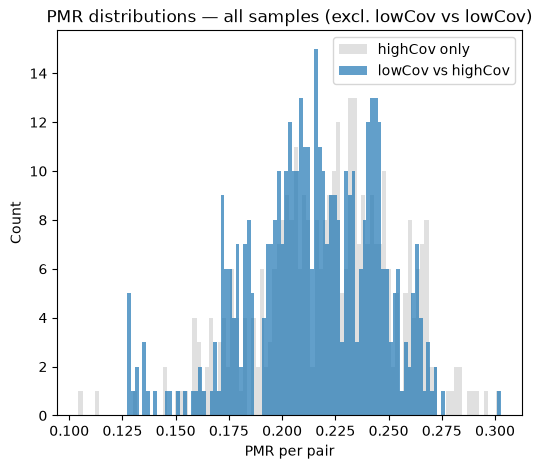

In [55]:
# stack high-cov and low-cov together: [n_snps, 27] + [n_snps, 16] -> [n_snps, 43]
gts_all = np.hstack([ph_merged_reloaded, lowcov_01_reloaded]).T  # transpose -> [n_iids, n_snps]
iids_all = np.concatenate([samples_merged_reloaded, lowcov_samples_reloaded])

df_pmr_all = pw_mm_rates_iids(gts=gts_all, iids=iids_all, val_missing=-1)

highcov_set = set(samples_merged_reloaded)
lowcov_set = set(lowcov_samples_reloaded)

def classify(row):
    id1_lowcov = row["iid1"] in lowcov_set
    id2_lowcov = row["iid2"] in lowcov_set
    if id1_lowcov and id2_lowcov:
        return "lowCov vs lowCov"
    elif id1_lowcov or id2_lowcov:
        return "lowCov vs highCov"
    else:
        return "highCov only"

df_pmr_all["comparison_type"] = df_pmr_all.apply(classify, axis=1)

# drop low vs low
df_pmr_all = df_pmr_all[df_pmr_all["comparison_type"] != "lowCov vs lowCov"].copy()

print(df_pmr_all["comparison_type"].value_counts())

df_pmr_all.to_csv(
    "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/pseudo_haps/pmr_all_python.csv",
    index=False
)

plt.figure(figsize=(6, 5))
ax = plt.gca()

category_colors = {
    "highCov only": "lightgrey",
    "lowCov vs highCov": "tab:blue",
}

for label, color in category_colors.items():
    if label in df_pmr_all["comparison_type"].values:
        group = df_pmr_all[df_pmr_all["comparison_type"] == label]
        ax.hist(group["pmr"], bins=100, alpha=0.7, label=label, color=color)

ax.set_xlabel("PMR per pair")
ax.set_ylabel("Count")
ax.set_title("PMR distributions — all samples (excl. lowCov vs lowCov)")
ax.legend()
plt.show()

In [49]:
ph_merged_reloaded

array([[ 0,  0,  1, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       ...,
       [ 0,  0,  0, ...,  0,  1,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0, -1]], shape=(537048, 27), dtype=int8)